<a href="https://colab.research.google.com/github/mohammad-mustafa130/Alzheimers-MRI-Classification/blob/main/Alzheimers_MRI_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys
import os

print("Alzheimer MRI Classification Project")
print("------------------------------------")

print("Python Version:", sys.version)
print("Current Directory:", os.getcwd())

# Check TensorFlow installation
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

# Check GPU availability
print("Available GPU:", tf.config.list_physical_devices('GPU'))


Alzheimer MRI Classification Project
------------------------------------
Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Current Directory: /content
TensorFlow Version: 2.21.0
Available GPU: []


In [2]:

from google.colab import drive

# Connect Google Drive with Colab
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:

import os

dataset_folder = "/content/drive/MyDrive/Alzheimers_MRI_Project/dataset"

print("Files inside dataset folder:")

for file in os.listdir(dataset_folder):
    print(file)


Files inside dataset folder:
Alzheimer (Preprocessed Data).zip


In [4]:

import zipfile
import os

zip_path = os.path.join(
    dataset_folder,
    "Alzheimer (Preprocessed Data).zip"
)

extract_path = "/content/alzheimers_dataset"

# Extract dataset
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Extraction location:", extract_path)


Dataset extracted successfully!
Extraction location: /content/alzheimers_dataset


In [5]:
import os

dataset_path = "/content/alzheimers_dataset"

print("DATASET FOLDER STRUCTURE")
print("========================")

# Check whether the extraction folder exists
print("Folder exists:", os.path.exists(dataset_path))

# Display files and folders
print("\nContents of extraction folder:")

for item in os.listdir(dataset_path):
    item_path = os.path.join(dataset_path, item)

    if os.path.isdir(item_path):
        print("📁 Folder:", item)
    else:
        print("📄 File:", item)

DATASET FOLDER STRUCTURE
Folder exists: True

Contents of extraction folder:
📁 Folder: Alzheimer (Preprocessed Data)


In [6]:
import os

dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

print("INSIDE ALZHEIMER DATASET")
print("========================")

for item in os.listdir(dataset_path):
    item_path = os.path.join(dataset_path, item)

    if os.path.isdir(item_path):
        print("📁 Folder:", item)
    else:
        print("📄 File:", item)

INSIDE ALZHEIMER DATASET
📁 Folder: Moderate_Demented
📁 Folder: Very_Mild_Demented
📁 Folder: Mild_Demented
📁 Folder: Non_Demented


In [7]:
import os

dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

print("NUMBER OF IMAGES IN EACH CLASS")
print("--------------------------------")

total_images = 0

for class_name in os.listdir(dataset_path):

    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):

        images = os.listdir(class_path)

        image_count = len(images)

        total_images += image_count

        print(class_name, ":", image_count)

print("--------------------------------")
print("Total Images:", total_images)

NUMBER OF IMAGES IN EACH CLASS
--------------------------------
Moderate_Demented : 64
Very_Mild_Demented : 2240
Mild_Demented : 896
Non_Demented : 3200
--------------------------------
Total Images: 6400


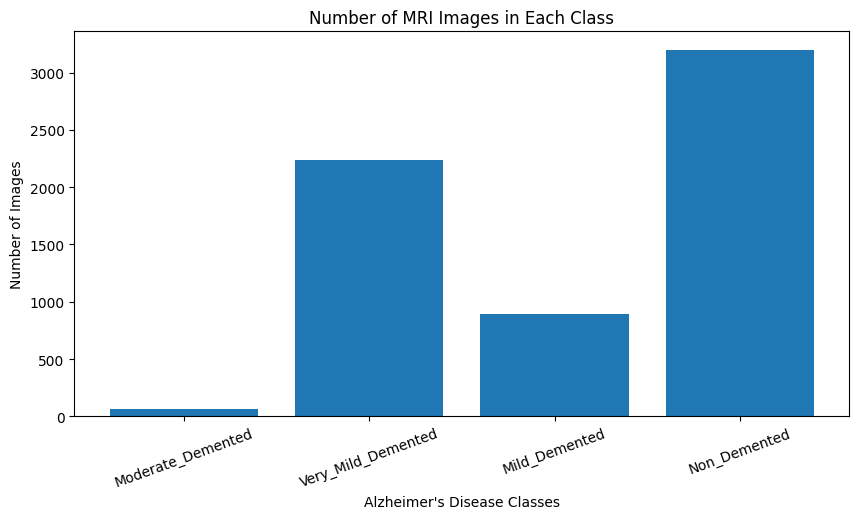

In [8]:
import os
import matplotlib.pyplot as plt

dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

class_names = []
image_counts = []

for class_name in os.listdir(dataset_path):

    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):

        count = len(os.listdir(class_path))

        class_names.append(class_name)
        image_counts.append(count)

# Create bar chart
plt.figure(figsize=(10, 5))

plt.bar(class_names, image_counts)

plt.title("Number of MRI Images in Each Class")
plt.xlabel("Alzheimer's Disease Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=20)
plt.show()

In [9]:
import os
import numpy as np
from PIL import Image

dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

class_names = [
    "Non_Demented",
    "Very_Mild_Demented",
    "Mild_Demented",
    "Moderate_Demented"
]

print("MRI PIXEL VALUE INSPECTION")
print("==========================")

for class_name in class_names:

    class_path = os.path.join(dataset_path, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    image_path = os.path.join(class_path, image_files[0])

    image = Image.open(image_path)

    image_array = np.array(image)

    print("\nClass:", class_name)
    print("Image shape:", image_array.shape)
    print("Data type:", image_array.dtype)
    print("Minimum pixel value:", np.min(image_array))
    print("Maximum pixel value:", np.max(image_array))
    print("Average pixel value:", np.mean(image_array))

MRI PIXEL VALUE INSPECTION

Class: Non_Demented
Image shape: (128, 128)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 254
Average pixel value: 78.60406494140625

Class: Very_Mild_Demented
Image shape: (128, 128)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Average pixel value: 70.36846923828125

Class: Mild_Demented
Image shape: (128, 128)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Average pixel value: 58.74395751953125

Class: Moderate_Demented
Image shape: (128, 128)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 252
Average pixel value: 60.9266357421875


In [10]:
import os
import numpy as np
from PIL import Image

# Select the Non_Demented class
class_path = os.path.join(dataset_path, "Non_Demented")

# Get the first image filename
image_name = os.listdir(class_path)[0]

# Create the complete image path
image_path = os.path.join(class_path, image_name)

# Open the MRI image
image = Image.open(image_path)

# Convert image into a NumPy array
image_array = np.array(image)

# Normalize pixel values
normalized_image = image_array.astype("float32") / 255.0

# Compare original and normalized images
print("BEFORE NORMALIZATION")
print("Data type:", image_array.dtype)
print("Minimum:", image_array.min())
print("Maximum:", image_array.max())

print("\nAFTER NORMALIZATION")
print("Data type:", normalized_image.dtype)
print("Minimum:", normalized_image.min())
print("Maximum:", normalized_image.max())

print("\nFirst 10 original pixel values:")
print(image_array[64, :10])

print("\nFirst 10 normalized pixel values:")
print(normalized_image[64, :10])

BEFORE NORMALIZATION
Data type: uint8
Minimum: 0
Maximum: 254

AFTER NORMALIZATION
Data type: float32
Minimum: 0.0
Maximum: 0.99607843

First 10 original pixel values:
[0 0 0 0 0 0 0 0 0 0]

First 10 normalized pixel values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [14]:
variables = [
    "image_paths",
    "labels",
    "train_paths",
    "train_labels",
    "val_paths",
    "val_labels",
    "test_paths",
    "test_labels",
    "train_labels_encoded",
    "val_labels_encoded",
    "test_labels_encoded",
    "train_dataset",
    "load_image"
]

for variable in variables:
    print(variable, ":", variable in globals())

image_paths : False
labels : False
train_paths : False
train_labels : False
val_paths : False
val_labels : False
test_paths : False
test_labels : False
train_labels_encoded : False
val_labels_encoded : False
test_labels_encoded : False
train_dataset : False
load_image : False


In [15]:
import os

# Location of our MRI dataset
dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

# Our four Alzheimer's classes
class_names = [
    "Non_Demented",
    "Very_Mild_Demented",
    "Mild_Demented",
    "Moderate_Demented"
]

# Empty lists for image paths and labels
image_paths = []
labels = []

# Read all MRI image paths
for class_name in class_names:

    class_path = os.path.join(dataset_path, class_name)

    for filename in sorted(os.listdir(class_path)):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            image_paths.append(
                os.path.join(class_path, filename)
            )

            labels.append(class_name)

print("IMAGE PATHS RESTORED")
print("====================")
print("Total image paths:", len(image_paths))
print("Total labels:", len(labels))

IMAGE PATHS RESTORED
Total image paths: 6400
Total labels: 6400


In [16]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: divide temporary data equally
# 15% validation and 15% testing
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("DATASET SPLIT RESTORED")
print("======================")
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))
print("Total images:",
      len(train_paths) + len(val_paths) + len(test_paths))

DATASET SPLIT RESTORED
Training images: 4480
Validation images: 960
Testing images: 960
Total images: 6400


In [17]:
# Define the class-to-number mapping
class_to_index = {
    "Non_Demented": 0,
    "Very_Mild_Demented": 1,
    "Mild_Demented": 2,
    "Moderate_Demented": 3
}

# Encode training labels
train_labels_encoded = [
    class_to_index[label] for label in train_labels
]

# Encode validation labels
val_labels_encoded = [
    class_to_index[label] for label in val_labels
]

# Encode testing labels
test_labels_encoded = [
    class_to_index[label] for label in test_labels
]

print("NUMERICAL LABELS RESTORED")
print("=========================")

print("Training labels:", len(train_labels_encoded))
print("Validation labels:", len(val_labels_encoded))
print("Testing labels:", len(test_labels_encoded))

print("\nFirst 5 original labels:", train_labels[:5])
print("First 5 encoded labels:", train_labels_encoded[:5])

NUMERICAL LABELS RESTORED
Training labels: 4480
Validation labels: 960
Testing labels: 960

First 5 original labels: ['Very_Mild_Demented', 'Moderate_Demented', 'Non_Demented', 'Very_Mild_Demented', 'Non_Demented']
First 5 encoded labels: [1, 3, 0, 1, 0]


In [18]:
import tensorflow as tf

def load_image(image_path, label):

    # Read the MRI image file
    image = tf.io.read_file(image_path)

    # Decode JPEG image as grayscale
    image = tf.image.decode_jpeg(image, channels=1)

    # Normalize pixel values from 0–255 to 0–1
    image = tf.image.convert_image_dtype(image, tf.float32)

    # Ensure the expected CNN input shape
    image = tf.ensure_shape(image, [128, 128, 1])

    return image, label

print("Image-loading function restored successfully!")

Image-loading function restored successfully!


In [19]:
# Create training dataset
train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels_encoded)
)

# Create validation dataset
val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels_encoded)
)

# Create testing dataset
test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels_encoded)
)

print("TENSORFLOW DATASETS RESTORED")
print("============================")
print("Training images:", train_dataset.cardinality().numpy())
print("Validation images:", val_dataset.cardinality().numpy())
print("Testing images:", test_dataset.cardinality().numpy())

TENSORFLOW DATASETS RESTORED
Training images: 4480
Validation images: 960
Testing images: 960


In [20]:
# Apply preprocessing to the training dataset
train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Apply preprocessing to the validation dataset
val_dataset = val_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Apply preprocessing to the testing dataset
test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("IMAGE PREPROCESSING APPLIED")
print("===========================")

# Inspect one processed training image
for image, label in train_dataset.take(1):

    print("Image shape:", image.shape)
    print("Image data type:", image.dtype)
    print("Minimum pixel value:", tf.reduce_min(image).numpy())
    print("Maximum pixel value:", tf.reduce_max(image).numpy())
    print("Encoded label:", label.numpy())

IMAGE PREPROCESSING APPLIED
Image shape: (128, 128, 1)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 0.9843138
Encoded label: 1


In [21]:
# Define batch size
BATCH_SIZE = 32

# Organize datasets into batches
train_dataset = train_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)

print("BATCHING COMPLETED")
print("==================")

# Inspect one training batch
for images, labels in train_dataset.take(1):

    print("Batch image shape:", images.shape)
    print("Batch label shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Labels:", labels.numpy())

BATCHING COMPLETED
Batch image shape: (32, 128, 128, 1)
Batch label shape: (32,)
Image data type: <dtype: 'float32'>
Labels: [1 3 0 1 0 0 2 2 0 0 0 1 1 1 1 0 1 0 0 0 0 0 0 0 0 0 2 0 1 0 0 0]


In [22]:
# Recreate the training dataset from paths and labels
train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels_encoded)
)

# Shuffle training examples
train_dataset = train_dataset.shuffle(
    buffer_size=len(train_paths),
    seed=42,
    reshuffle_each_iteration=True
)

# Load and normalize MRI images
train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Group images into batches
train_dataset = train_dataset.batch(32)

print("TRAINING DATASET SHUFFLED SUCCESSFULLY")
print("======================================")

# Inspect the first batch
for images, labels in train_dataset.take(1):
    print("Batch image shape:", images.shape)
    print("Batch label shape:", labels.shape)
    print("First 10 labels:", labels.numpy()[:10])

TRAINING DATASET SHUFFLED SUCCESSFULLY
Batch image shape: (32, 128, 128, 1)
Batch label shape: (32,)
First 10 labels: [0 1 0 0 0 0 0 2 0 1]


In [23]:
# Enable automatic prefetch optimization
AUTOTUNE = tf.data.AUTOTUNE

# Apply prefetching to all three datasets
train_dataset = train_dataset.prefetch(AUTOTUNE)
val_dataset = val_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

print("PREFETCHING COMPLETED")
print("=====================")

print("Training batches:", train_dataset.cardinality().numpy())
print("Validation batches:", val_dataset.cardinality().numpy())
print("Testing batches:", test_dataset.cardinality().numpy())

PREFETCHING COMPLETED
Training batches: 140
Validation batches: 30
Testing batches: 30


In [24]:
from tensorflow.keras import layers, models

# Create our CNN model
model = models.Sequential([

    # Input layer
    layers.Input(shape=(128, 128, 1)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a feature vector
    layers.GlobalAveragePooling2D(),

    # Fully connected layer
    layers.Dense(64, activation="relu"),

    # Reduce overfitting
    layers.Dropout(0.3),

    # Output layer for 4 Alzheimer's classes
    layers.Dense(4, activation="softmax")
])

print("CNN MODEL CREATED SUCCESSFULLY")

CNN MODEL CREATED SUCCESSFULLY


In [25]:
# Display the complete CNN architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,188 (395.27 KB)

 Trainable params: 101,188 (395.27 KB)

 Non-trainable params: 0 (0.00 B)